<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/main/arxiv_abstracts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ArXiv Abstracts

In [22]:
from pathlib import Path
import runpy

ROOT = Path("/content/rhetorical_signatures")
_INITIALIZER = ROOT / "code" / "initialize_experiment.py"
if not _INITIALIZER.is_file():
    raise FileNotFoundError(f"Missing initializer: {_INITIALIZER}")

# run_path returns the variables defined by the initialization script;
# publish them to notebook globals for compatibility with cells 02 onward.
globals().update(runpy.run_path(str(_INITIALIZER)))


Environment ready
-------------------------------------------------------
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
spaCy: 3.8.18

Dataset selection
-------------------------------------------------------
Selection algorithm version: 2
Sampling: proportional
Sentence range: 6–10
Number of bins: 10
Seed: 42
Include Human: True

RST parsing
-------------------------------------------------------
Number of sentences: 6
Matched: False
Model: tchewik/isanlp_rst_v3
Model version: rstdt
Device: auto
Document limit: None
Retry errors: False

XML forests
-------------------------------------------------------
Grouping variables: ['genre', 'source', 'n_sentences']
Rebuild: False
Validate: True
External metadata: None

TreeRePair compression
-------------------------------------------------------
Genre: abstracts
Sentences: 6
Sources: None
Rebuild: False
Textual grammar: True
Optimization: filesize
Max rank: None
Timeout: 600s

TreeDePair validation
-----------------------------

In [23]:
# ------------------------------------------------------------
# RAID dataset availability
# ------------------------------------------------------------

raid_downloader = load_project_module(
    "raid_downloader",
    PROCESSING_DIR / "01_download_raid.py",
)

raid_downloader.download_raid()

RAID dataset already available: /content/rhetorical_signatures/data/raw/raid/train.csv


PosixPath('/content/rhetorical_signatures/data/raw/raid/train.csv')

In [24]:
documents, sentences = process_sentences.load_or_analyze_sentence_lengths(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    rebuild=SENTENCE_ANALYSIS_REBUILD,
    show_progress=SENTENCE_ANALYSIS_SHOW_PROGRESS,
)

sentence_stats = sentences.merge(
    documents[["id", "source"]],
    on="id",
    how="left",
    validate="many_to_one",
)

assert sentence_stats["source"].notna().all()

print(
    f"{len(documents):,} documents | "
    f"{len(sentences):,} sentences | "
    f"{documents['source'].nunique()} sources"
)

Loaded existing sentence analysis: /content/rhetorical_signatures/results/sentences_report/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no
12,362 documents | 93,427 sentences | 7 sources


In [25]:
source_order = [
    source for source in MODEL_ORDER
    if source in documents["source"].unique()
]

document_summary = (
    documents.groupby("source")
    .agg(
        documents=("id", "size"),
        median_sentences=("n_sentences", "median"),
        mean_sentences=("n_sentences", "mean"),
        median_words=("n_words", "median"),
        mean_words=("n_words", "mean"),
    )
    .reindex(source_order)
)

sentence_summary = (
    sentence_stats.groupby("source")
    .agg(
        sentences=("id", "size"),
        median_words_per_sentence=("n_words", "median"),
        mean_words_per_sentence=("n_words", "mean"),
    )
    .reindex(source_order)
)

descriptive_summary = document_summary.join(sentence_summary)

display(
    descriptive_summary.style.format({
        "documents": "{:,.0f}",
        "sentences": "{:,.0f}",
        "median_sentences": "{:.1f}",
        "mean_sentences": "{:.1f}",
        "median_words": "{:.1f}",
        "mean_words": "{:.1f}",
        "median_words_per_sentence": "{:.1f}",
        "mean_words_per_sentence": "{:.1f}",
    })
)

,documents,median_sentences,mean_sentences,median_words,mean_words,sentences,median_words_per_sentence,mean_words_per_sentence
source,,,,,,,,
Human,"1,766",7.0,7.6,171.0,175.6,"13,401",22.0,23.1
ChatGPT,"1,766",6.0,5.8,115.0,118.1,"10,157",20.0,20.5
GPT-4,"1,766",5.0,5.2,106.0,107.2,"9,111",20.0,20.8
Mistral 7B,"1,766",16.0,15.8,319.0,278.3,"27,957",17.0,17.6
Mistral 7B (Chat),"1,766",6.0,5.9,126.0,132.0,"10,371",22.0,22.5
Cohere,"1,766",6.0,6.3,137.0,145.5,"11,161",22.0,23.0
Cohere (Chat),"1,766",6.0,6.4,134.0,142.4,"11,269",21.0,22.3


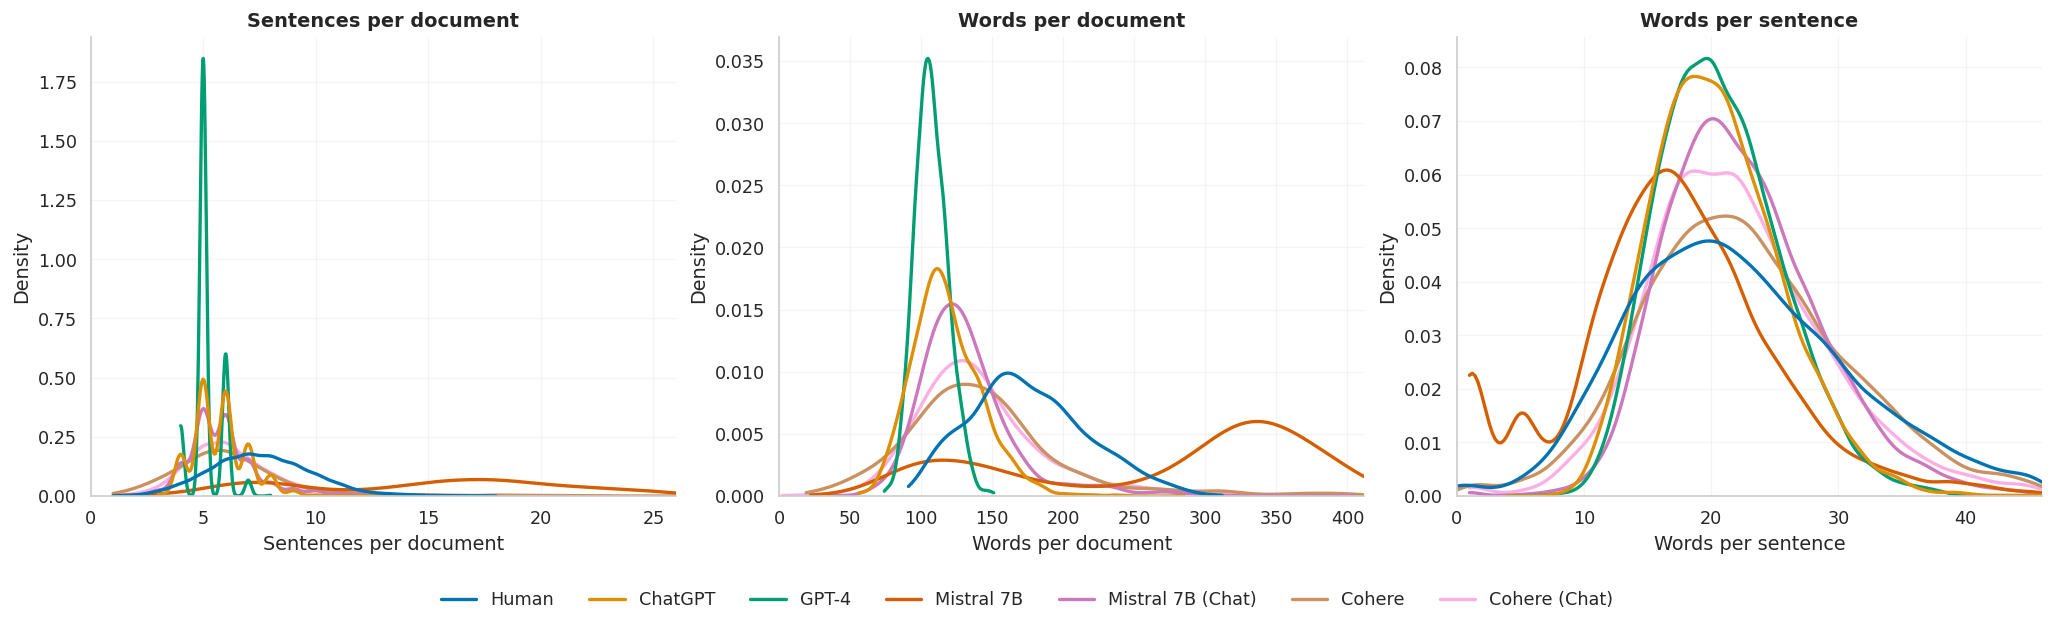

In [26]:

fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.6), constrained_layout=True
)

variables = [
    (documents, "n_sentences", "Sentences per document"),
    (documents, "n_words", "Words per document"),
    (sentence_stats, "n_words", "Words per sentence"),
]

palette = dict(zip(
    source_order,
    sns.color_palette("colorblind", n_colors=len(source_order))
))

for ax, (data, column, xlabel) in zip(axes, variables):
    upper = data[column].quantile(0.99)

    subset = data.loc[
        data[column].notna() & data[column].le(upper)
    ].copy()

    sns.kdeplot(
        data=subset,
        x=column,
        hue="source",
        hue_order=source_order,
        palette=palette,
        common_norm=False,
        bw_adjust=1.0,
        cut=0,
        clip=(0, None),
        linewidth=2,
        fill=False,
        warn_singular=False,
        ax=ax,
        legend=False,
    )

    ax.set(
        xlabel=xlabel,
        ylabel="Density",
        title=xlabel,
    )
    ax.set_xlim(left=0, right=upper)
    ax.grid(alpha=0.2)

from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        color=palette[source],
        lw=2,
        label=source,
    )
    for source in source_order
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(source_order), 7),
)

plt.show()

Loaded selection: /content/rhetorical_signatures/data/filtered/sentences/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-1__proportional__seed-42__bins-10__human-1
Loaded selection: /content/rhetorical_signatures/data/filtered/sentences/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1
Matched: n=6, 76 documents per source
Unmatched: n=6, 421 documents per source


,selection,source,best_n,eligible,selected
0,Matched,Human,6,1465,76
1,Matched,ChatGPT,6,947,76
2,Matched,GPT-4,6,421,76
3,Matched,Mistral 7B,6,1690,76
4,Matched,Mistral 7B (Chat),6,956,76
5,Matched,Cohere,6,1022,76
6,Matched,Cohere (Chat),6,1091,76
7,Unmatched,Human,6,1465,421
8,Unmatched,ChatGPT,6,947,421
9,Unmatched,GPT-4,6,421,421


,selection,source,median_before,median_after,wasserstein
0,Matched,Human,134.0,124.5,5.63
1,Matched,ChatGPT,118.0,115.5,2.60
2,Matched,GPT-4,116.0,116.5,1.68
3,Matched,Mistral 7B,99.0,99.0,2.75
4,Matched,Mistral 7B (Chat),128.5,125.5,3.57
5,Matched,Cohere,133.0,120.0,7.90
6,Matched,Cohere (Chat),129.0,127.0,4.78
7,Unmatched,Human,134.0,134.0,0.67
8,Unmatched,ChatGPT,118.0,117.0,0.23
9,Unmatched,GPT-4,116.0,116.0,0.00


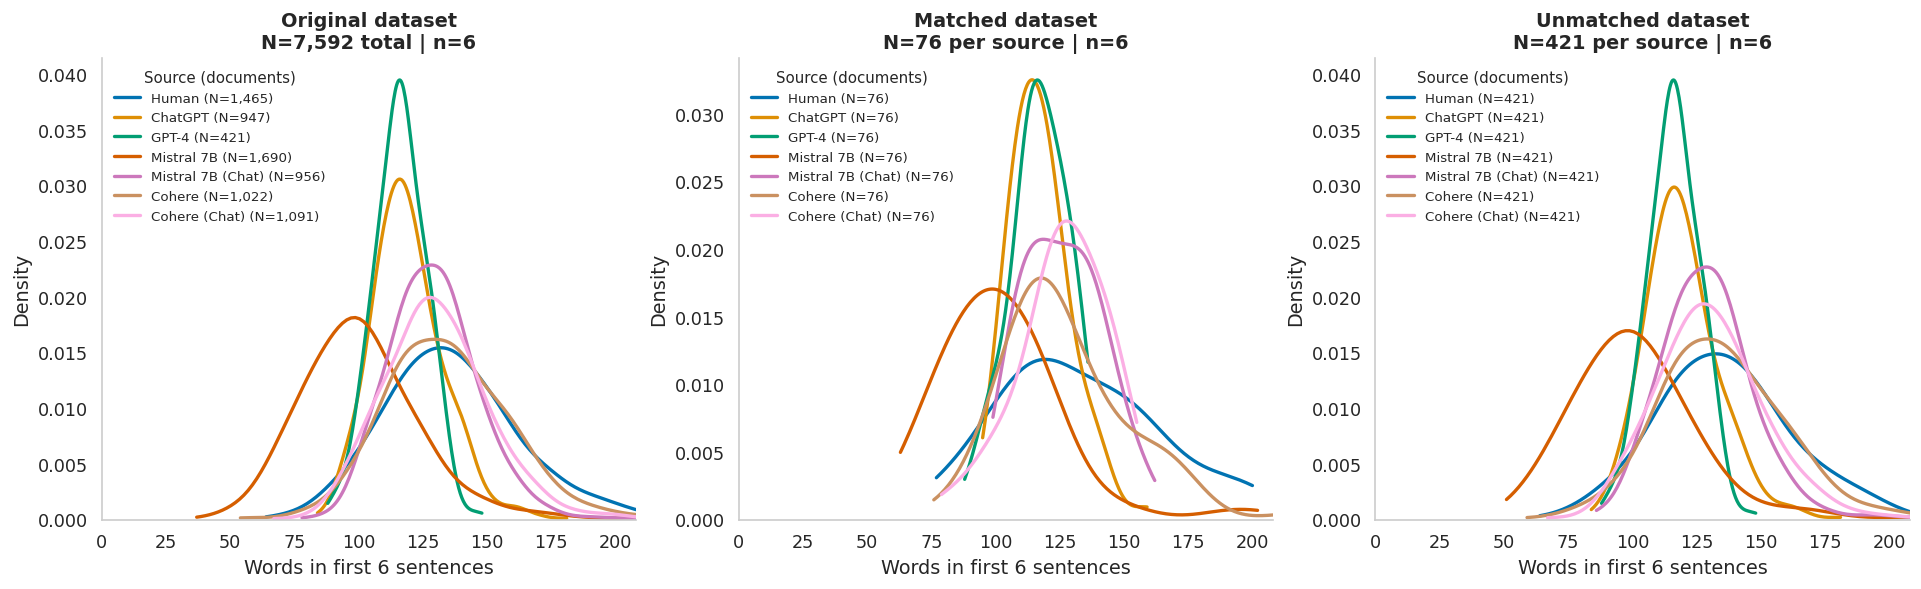

In [27]:
# Selection and diagnostics — no helper definitions in the notebook
selection_kwargs = dict(
    documents=documents, sentences=sentences,
    min_sentences=MIN_SENTENCES, max_sentences=MAX_SENTENCES,
    domain=DOMAIN, prompting=PROMPTING, attack=ATTACK,
    decoding=DECODING, repetition_penalty=REPETITION_PENALTY,
    sampling=SAMPLING, n_bins=N_BINS, seed=SEED,
    include_human=INCLUDE_HUMAN,
)

selected_matched, comparison_matched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=True
    )
)
selected_unmatched, comparison_unmatched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=False
    )
)

count_summary, distribution_check = process_sentences.selection_diagnostics(
    documents, sentences,
    {
        'Matched': (selected_matched, comparison_matched),
        'Unmatched': (selected_unmatched, comparison_unmatched),
    },
)


### Parsing

In [28]:
# ============================================================
# 02 — Load or parse RST trees
# ============================================================

output, trees = rst.load_or_parse_dataset(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    min_sentences=MIN_SENTENCES,
    max_sentences=MAX_SENTENCES,
    n_sentences=N_SENTENCES,
    matched=RST_MATCHED,
    sampling=SAMPLING,
    seed=SEED,
    n_bins=N_BINS,
    include_human=INCLUDE_HUMAN,
    model=RST_MODEL,
    model_version=RST_MODEL_VERSION,
    device=RST_DEVICE,
    retry_errors=RST_RETRY_ERRORS,
    limit=RST_LIMIT,
    rebuild=RST_REBUILD,
    output_root=RST_DATA_DIR,
)

print(f"RST trees loaded: {len(trees)}")
print(f"Output: {output}")

RST cache: 2947/2947 successful; 0 previous failures; 0 to parse


RST parsing (n=6): 0it [00:00, ?it/s]

Loaded existing dataset: /content/rhetorical_signatures/data/filtered/sentences/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1
RST output: /content/rhetorical_signatures/data/rst/unmatched/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1
RST trees loaded: 2947
Output: /content/rhetorical_signatures/data/rst/unmatched/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1


### Build forests

In [29]:
# ============================================================
# 03 — Load or build grouped XML forests
# ============================================================

(
    forests_dir,
    forest_paths,
    forest_index,
    manifest,
) = forest_builder.load_or_build_forests(
    trees_file=Path(output) / "trees.jsonl",
    metadata_file=FOREST_METADATA_FILE,
    group_by=FOREST_GROUP_BY,
    rebuild=FOREST_REBUILD,
    validate=FOREST_VALIDATE,
)


XML FORESTS READY
Forests: 7
RST trees: 2947
Directory: /content/rhetorical_signatures/data/rst/unmatched/domain-abstracts__prompting-all__attack-null__decoding-greedy__rep-no/range-6-10__best-6__matched-0__proportional__seed-42__bins-10__human-1/forests


# TreeRePair

In [30]:

# ============================================================
# 04 — TreeRePair grammar compression
# ============================================================

compression_dir, compression_results, compression_manifest = (
    tree_compressor.run_treerepair(
        forests_dir=forests_dir,
        binary=TREEREPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=COMPRESSION_REBUILD,
        textual=COMPRESSION_TEXTUAL,
        optimize=COMPRESSION_OPTIMIZE,
        max_rank=COMPRESSION_MAX_RANK,
        timeout=COMPRESSION_TIMEOUT,
        continue_on_error=COMPRESSION_CONTINUE_ON_ERROR,
    )
)

compression_summary = pd.DataFrame(compression_results)

display(compression_summary)


[1/7] ChatGPT
  Cached grammar reused
[2/7] Cohere
  Cached grammar reused
[3/7] Cohere_Chat
  Cached grammar reused
[4/7] GPT-4
  Cached grammar reused
[5/7] Human
  Cached grammar reused
[6/7] Mistral_7B
  Cached grammar reused
[7/7] Mistral_7B_Chat
  Cached grammar reused


,source,forest,status,returncode,cached,rep_file,reptxt_file,rep_bytes,reptxt_bytes,forest_sha256
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,7345,31328,c7526cc8f6ad7ff53e48a99062bf40f15aac5755ab2d06...
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,8439,35861,6af51c90d53761b9969ee827918efebb1539fedaf11b48...
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,8034,33953,44b6d184de07655f8f6a7cac89fb69fbb0d11dfb1dab31...
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6898,28906,d51cc455ae6b7384066191a553990bae182e867d8e4573...
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,8827,37195,10c3d8dbc6fe219381d7779be4fb21eb6ddbe0784b26ce...
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6409,26162,1b5176170f213c7010e5137950e4d1e7595a7a6c252dcc...
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,CACHED_UNVALIDATED,0,True,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,7470,31769,56bdba5ac90461a1d05df29a7a3c859c0890c356f4810e...


In [31]:

# ============================================================
# 05 — TreeRePair grammar validation
# ============================================================

validation_dir, validation_results, validation_manifest = (
    grammar_validator.validate_grammars(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        binary=TREEDEPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=VALIDATION_REBUILD,
        timeout=VALIDATION_TIMEOUT,
        keep_reconstructed=VALIDATION_KEEP_RECONSTRUCTED,
    )
)

validation_summary = pd.DataFrame(validation_results)

display(validation_summary)


[1/7] ChatGPT
  VALIDATED (cached)
[2/7] Cohere
  VALIDATED (cached)
[3/7] Cohere_Chat
  VALIDATED (cached)
[4/7] GPT-4
  VALIDATED (cached)
[5/7] Human
  VALIDATED (cached)
[6/7] Mistral_7B
  VALIDATED (cached)
[7/7] Mistral_7B_Chat
  VALIDATED (cached)


,source,forest,rep_file,restored_file,cached,returncode,original_trees,reconstructed_trees,document_ids_match,structure_match,original_root,reconstructed_root,validated,status
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED
5,Mistral_7B,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED
6,Mistral_7B_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,421,421,True,True,forest,forest,True,VALIDATED


### Extract Motifs

In [32]:
# CELL 06 — Extract RST motifs

motifs_dir, motif_results, motif_manifest = (
    motif_extractor.extract_motifs(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=MOTIF_REBUILD,
        min_relations=MOTIF_MIN_RELATIONS,
        min_depth=MOTIF_MIN_DEPTH,
        include_wildcards=MOTIF_INCLUDE_WILDCARDS,
        continue_on_error=MOTIF_CONTINUE_ON_ERROR,
    )
)

display(pd.DataFrame(motif_results))

print(f"\nMotifs saved to: {motifs_dir}")

[1/7] genre-abstracts__n_sentences-6 / ChatGPT
  Cached: 114 motifs
[2/7] genre-abstracts__n_sentences-6 / Cohere
  Cached: 129 motifs
[3/7] genre-abstracts__n_sentences-6 / Cohere_Chat
  Cached: 78 motifs
[4/7] genre-abstracts__n_sentences-6 / GPT-4
  Cached: 103 motifs
[5/7] genre-abstracts__n_sentences-6 / Human
  Cached: 103 motifs
[6/7] genre-abstracts__n_sentences-6 / Mistral_7B
  Cached: 122 motifs
[7/7] genre-abstracts__n_sentences-6 / Mistral_7B_Chat
  Cached: 114 motifs


,dataset,source,status,n_motifs,n_wildcard_motifs,n_grammar_templates,cached,output_dir
0,genre-abstracts__n_sentences-6,ChatGPT,COMPLETED,114,54,114,True,/content/rhetorical_signatures/results/sentenc...
1,genre-abstracts__n_sentences-6,Cohere,COMPLETED,129,62,129,True,/content/rhetorical_signatures/results/sentenc...
2,genre-abstracts__n_sentences-6,Cohere_Chat,COMPLETED,78,28,78,True,/content/rhetorical_signatures/results/sentenc...
3,genre-abstracts__n_sentences-6,GPT-4,COMPLETED,103,45,103,True,/content/rhetorical_signatures/results/sentenc...
4,genre-abstracts__n_sentences-6,Human,COMPLETED,103,43,103,True,/content/rhetorical_signatures/results/sentenc...
5,genre-abstracts__n_sentences-6,Mistral_7B,COMPLETED,122,63,122,True,/content/rhetorical_signatures/results/sentenc...
6,genre-abstracts__n_sentences-6,Mistral_7B_Chat,COMPLETED,114,58,114,True,/content/rhetorical_signatures/results/sentenc...



Motifs saved to: /content/rhetorical_signatures/results/sentences_report/motifs/genre-abstracts__n_sentences-6


In [39]:
'''
# CELL 07 — Display all motifs, grouped by source
all_motifs = motif_extractor.display_motifs(
    motifs_dir,
    show_grammar_symbols=True,
)
'''

'\n# CELL 07 — Display all motifs, grouped by source\nall_motifs = motif_extractor.display_motifs(\n    motifs_dir,\n    show_grammar_symbols=True,\n)\n'